# SPOT vs STLSat — formal equivalence on the ATIC manual-review sample

**Data**: the 151 condition-level rows of `ATIC_ManualReview` collapse to **110 unique (gold, pred) pairs**
(every `review_id` has exactly one formula pair). All numbers below are per unique pair.

**Regenerate results** (≈ 5 + 3 min):
```bash
python -m equivalence --dataset manual_review --out data/results/manual_review_smt.csv
python -m equivalence --dataset manual_review --no-spot --engine tableau --out data/results/manual_review_tableau.csv
```
Verdicts are always *prediction relative to gold*: `EQUIVALENT`, `PRED_STRONGER` (stricter), `PRED_WEAKER` (looser), `INCOMPARABLE`.
Semantics decisions (discrete time, standard until, Y false at t=0, horizon capping for STLSat) are listed in `README.md`.

In [1]:
import subprocess, io
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option('display.max_colwidth', 110); pd.set_option('display.width', 200)

# reference palette (dataviz skill): fixed categorical order, recessive axes
BLUE, ORANGE, AQUA, YELLOW, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#9a9893'
TOOL_COLOR = {'Syntactic': AQUA, 'SPOT': BLUE, 'STLSat (smt)': ORANGE, 'STLSat (tableau)': YELLOW}
VERDICTS = ['EQUIVALENT', 'PRED_STRONGER', 'PRED_WEAKER', 'INCOMPARABLE']
VERDICT_COLOR = dict(zip(VERDICTS, [BLUE, ORANGE, AQUA, YELLOW]))
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#b5b3ad',
                     'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
                     'axes.titleweight': 'bold', 'axes.titlesize': 11, 'font.size': 10,
                     'axes.grid': True, 'grid.color': '#e8e7e3', 'grid.linewidth': 0.6, 'axes.axisbelow': True})

smt = pd.read_csv('data/results/manual_review_smt.csv')
tab = pd.read_csv('data/results/manual_review_tableau.csv')
smt = smt.merge(tab[['pair_id', 'stlsat_status', 'stlsat_verdict', 'stlsat_ms', 'stlsat_wall_ms', 'stlsat_detail']]
                .add_prefix('tab_').rename(columns={'tab_pair_id': 'pair_id'}), on='pair_id')
d = smt
print(len(d), 'unique pairs;', d.n_condition_rows.sum(), 'condition rows')

110 unique pairs; 151 condition rows


## 1. Before vs after the rewrite

The previous pipeline's results are read straight from git (`HEAD`), deduplicated to the same 110 pairs.
Its binary verdicts are compared with the new ones on pairs where **new SPOT (exact, also for unbounded
operators) and new STLSat-smt agree**, which is the most trustworthy reference we have.

In [2]:
def old(path):
    raw = subprocess.run(['git', 'show', f'HEAD:ATIC_Equivalence/{path}'], capture_output=True, text=True, check=True).stdout
    return pd.read_csv(io.StringIO(raw)).drop_duplicates('review_id').rename(columns={'review_id': 'pair_id'})

old_spot, old_stlsat = old('data/spot_results.csv'), old('data/stlsat_results.csv')

def decided(s): return s.isin(['EQUIVALENT', 'NON_EQUIVALENT'])
cov = pd.DataFrame({
    'old SPOT':   [decided(old_spot.equiv_verdict).sum()],
    'new SPOT':   [(d.spot_status == 'OK').sum()],
    'old STLSat': [decided(old_stlsat.equiv_verdict).sum()],
    'new STLSat (smt)': [(d.stlsat_status == 'OK').sum()],
}, index=['pairs with a verdict (of 110)'])
display(cov)

ref = d[(d.spot_status == 'OK') & (d.stlsat_status == 'OK') & (d.spot_verdict == d.stlsat_verdict)]
ref_eq = ref.set_index('pair_id').spot_verdict.eq('EQUIVALENT')
rows = []
for name, o in [('old SPOT', old_spot), ('old STLSat', old_stlsat)]:
    o = o.set_index('pair_id').equiv_verdict.reindex(ref_eq.index)
    m = decided(o)
    wrong = (o[m].eq('EQUIVALENT') != ref_eq[m])
    rows.append({'tool': name, 'reference pairs': len(ref_eq), 'old tool decided': int(m.sum()),
                 'old verdict wrong': int(wrong.sum()), 'wrong ids': ', '.join(wrong[wrong].index)})
display(pd.DataFrame(rows))
# which way were the old mistakes?
for name, o in [('old SPOT', old_spot), ('old STLSat', old_stlsat)]:
    o = o.set_index('pair_id').equiv_verdict.reindex(ref_eq.index); m = decided(o)
    fe = (o[m].eq('EQUIVALENT') & ~ref_eq[m]).sum(); fn = (~o[m].eq('EQUIVALENT') & ref_eq[m]).sum()
    print(f'{name}: {fe} false EQUIVALENT, {fn} false NON_EQUIVALENT')

,old SPOT,new SPOT,old STLSat,new STLSat (smt)
pairs with a verdict (of 110),94,99,29,101


,tool,reference pairs,old tool decided,old verdict wrong,wrong ids
0,old SPOT,98,90,5,"MR-020, MR-023, MR-075, MR-081, MR-085"
1,old STLSat,98,27,6,"MR-005, MR-023, MR-047, MR-074, MR-100, MR-109"


old SPOT: 1 false EQUIVALENT, 4 false NON_EQUIVALENT
old STLSat: 0 false EQUIVALENT, 6 false NON_EQUIVALENT


Why the old verdicts were wrong (all confirmed by hand and by the tests in `tests/test_known_pairs.py`):

| old behaviour | effect |
|---|---|
| SPOT path **stripped all time bounds** | `F[0,15]` ≡ `F[0,20]` (MR-075), `F[0,120]` ≡ `F` (MR-089) → false EQUIVALENT |
| rise/fall rewritten to `Yφ`, **SPOT has no past operators** | `Yfault` was parsed as an unrelated atom named "Yfault" → past semantics lost |
| atoms not quoted | SPOT read the signals `Fsig`/`Gsig` as `F(sig)`/`G(sig)` (MR-040) |
| regex `\b[GF]` in the normaliser | `Fsig` became `F[0,100000]sig` |
| predicate abstraction by string mangling | `x < 20` and `x >= 20` unrelated atoms; `x1 + x2 <= 1.5` became `x1 + x2_le_1p5` |
| `x = 0 → x == 0` but `!x` stays Boolean (STLSat) | Boolean and real variable are different → false NON_EQUIVALENT (e.g. MR-005) |
| unbounded G/F capped at 100000 | 49 STLSat timeouts; and capping both sides identically is unsound (G vs G[0,600]) |
| `S` detection regex inverted | `p S q` never detected as past → sent to SPOT unchanged → parse error |
| per-formula interval scaling | gold and pred scaled by different factors |
| STLSat's own bugs (see README) | tableau unsound on some inputs; constants in (−1,0) lose their sign |

## 2. Coverage per tool

In [3]:
order = ['OK', 'UNSUPPORTED', 'TIMEOUT', 'TOOL_ERROR', 'PARSE_ERROR']
cov = pd.DataFrame({
    'Syntactic': pd.Series({'OK': d.parse_ok.sum()}),
    'SPOT': d.spot_status.value_counts(),
    'STLSat (smt)': d.stlsat_status.value_counts(),
    'STLSat (tableau)': d.tab_stlsat_status.value_counts(),
}).reindex(order).fillna(0).astype(int)
display(cov)
print('Syntactic stage proves EQUIVALENT for', int(d.syntactic_equal.sum()), 'pairs (canonical forms identical).')
print('STLSat verdicts relying on horizon capping (bounded_approx):', int((d.stlsat_bounded_approx.astype(bool) & (d.stlsat_status=='OK')).sum()))
display(d.loc[(d.spot_status != 'OK') | (d.stlsat_status != 'OK'),
              ['pair_id', 'spot_status', 'stlsat_status', 'tab_stlsat_status', 'max_bound', 'spot_detail', 'stlsat_detail']])

,Syntactic,SPOT,STLSat (smt),STLSat (tableau)
OK,110,99,101,95
UNSUPPORTED,0,8,8,8
TIMEOUT,0,3,1,7
TOOL_ERROR,0,0,0,0
PARSE_ERROR,0,0,0,0


Syntactic stage proves EQUIVALENT for 70 pairs (canonical forms identical).
STLSat verdicts relying on horizon capping (bounded_approx): 77


,pair_id,spot_status,stlsat_status,tab_stlsat_status,max_bound,spot_detail,stlsat_detail
17,MR-018,TIMEOUT,OK,TIMEOUT,20,timed out after 30.0s,unbounded operators capped at horizon 50
49,MR-050,OK,TIMEOUT,TIMEOUT,600,NaN,TIMEOUT: timed out after 30.0s; TIMEOUT: timed out after 30.0s
62,MR-063,TIMEOUT,OK,OK,150,timed out after 30.0s,NaN
81,MR-082,UNSUPPORTED,UNSUPPORTED,UNSUPPORTED,0,symbolic time bound 'T' in F,symbolic time bound (symbolic bound)
82,MR-083,UNSUPPORTED,UNSUPPORTED,UNSUPPORTED,0,symbolic time bound 'T' in F,symbolic time bound (symbolic bound)
83,MR-084,UNSUPPORTED,UNSUPPORTED,UNSUPPORTED,0,symbolic time bound 't' in G,symbolic time bound (symbolic bound)
85,MR-086,UNSUPPORTED,UNSUPPORTED,UNSUPPORTED,0,parametric operator AND_i<j(...),parametric operator AND_i<j(...)
86,MR-087,UNSUPPORTED,UNSUPPORTED,UNSUPPORTED,0,parametric operator AND_i<j(...),parametric operator AND_i<j(...)
88,MR-089,TIMEOUT,OK,TIMEOUT,120,timed out after 30.0s,unbounded operators capped at horizon 490
89,MR-090,UNSUPPORTED,UNSUPPORTED,UNSUPPORTED,300,parametric operator OR_i(...),parametric operator OR_i(...)


* **UNSUPPORTED (8)** are the same for both tools: symbolic time bounds (`F[0,T]`, `G[0,H]`) and parameterised
  operators (`AND_{i<j}`, `OR_i`). Several of them are still resolved by the syntactic stage (symmetric `distance`, `abs`).
* **Timeouts are complementary.** SPOT struggles with *large nested bounds* (`F[0,120](… F[0,120] …)` turns into
  ~120×120 X-steps); STLSat-smt struggles with *long horizons combined with unbounded operators* (MR-050: H = 1210).

## 3. Agreement between SPOT and STLSat

In [4]:
both = d[(d.spot_status == 'OK') & (d.stlsat_status == 'OK')]
ct = pd.crosstab(both.spot_verdict, both.stlsat_verdict, rownames=['SPOT'], colnames=['STLSat (smt)'])
display(ct)
print(f"{(both.spot_verdict == both.stlsat_verdict).sum()} / {len(both)} identical verdicts "
      f"({(both.stlsat_bounded_approx.astype(bool)).sum()} of the STLSat ones use horizon capping)")
tb = d[(d.tab_stlsat_status == 'OK') & (d.stlsat_status == 'OK')]
bad = tb[tb.tab_stlsat_verdict != tb.stlsat_verdict]
print(f"STLSat tableau vs smt: {len(tb) - len(bad)} / {len(tb)} identical")
display(bad[['pair_id', 'gold', 'pred', 'stlsat_verdict', 'tab_stlsat_verdict', 'spot_verdict']])

STLSat (smt),EQUIVALENT,INCOMPARABLE,PRED_STRONGER,PRED_WEAKER
SPOT,,,,
EQUIVALENT,73,0,0,0
INCOMPARABLE,0,5,0,0
PRED_STRONGER,0,0,7,0
PRED_WEAKER,0,0,0,13


98 / 98 identical verdicts (75 of the STLSat ones use horizon capping)
STLSat tableau vs smt: 94 / 95 identical


,pair_id,gold,pred,stlsat_verdict,tab_stlsat_verdict,spot_verdict
19,MR-020,"G((!((temperature >= 20) & (temperature <= 30))) -> F[0,6](G[0,4]((temperature >= 20) & (temperature <= 30...","G((temperature < 20 | temperature > 30) -> F[0,6](G[0,4](temperature >= 20 & temperature <= 30)))",EQUIVALENT,PRED_WEAKER,EQUIVALENT


SPOT and STLSat-smt decide the same semantics through completely independent encodings (automata over
X-expansions vs. SMT over bounded time), and the random differential test in `tests/test_differential.py`
(SPOT vs STLSat on random bounded formulas with past operators, edges and numeric predicates) finds no
disagreement. Where the two agree, the verdict can be trusted. Where the tableau engine deviates from smt,
SPOT sides with smt, so these are tableau errors (see the reproducer in the README).

## 4. Strictness verdicts

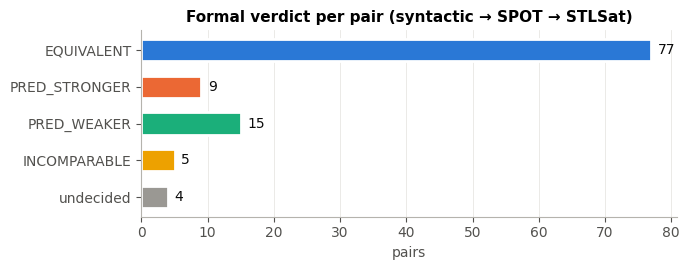

formal_source,-,SPOT,STLSat,syntactic
formal,,,,
EQUIVALENT,0,7,0,70
INCOMPARABLE,0,5,0,0
PRED_STRONGER,0,7,2,0
PRED_WEAKER,0,14,1,0
undecided,4,0,0,0


In [5]:
d['formal'] = np.where(d.syntactic_equal == True, 'EQUIVALENT',
              np.where(d.spot_status == 'OK', d.spot_verdict,
              np.where(d.stlsat_status == 'OK', d.stlsat_verdict, 'undecided')))
d['formal_source'] = np.where(d.syntactic_equal == True, 'syntactic',
                     np.where(d.spot_status == 'OK', 'SPOT', np.where(d.stlsat_status == 'OK', 'STLSat', '-')))
vc = d.formal.value_counts().reindex(VERDICTS + ['undecided']).fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(7, 2.8))
bars = ax.barh(vc.index[::-1], vc.values[::-1], color=[VERDICT_COLOR.get(k, GRAY) for k in vc.index[::-1]],
               height=0.6, edgecolor='white', linewidth=2)
for b, v in zip(bars, vc.values[::-1]):
    ax.text(b.get_width() + 1, b.get_y() + b.get_height() / 2, str(v), va='center', color='#0b0b0b')
ax.set_xlabel('pairs'); ax.set_title('Formal verdict per pair (syntactic → SPOT → STLSat)'); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()
display(pd.crosstab(d.formal, d.formal_source))

## 5. Formal verdict vs human adjudication

Human labels: `pass_equivalent` and `fail_clarification` both mean *the formula is acceptable*
(`fail_clarification` = the clarification question was wrong; see `ATIC_ManualReview/README.md`).

final_decision,fail_clarification,fail_semantic,pass_equivalent,accepted %
formal,,,,
EQUIVALENT,6,0,71,100.0
PRED_STRONGER,0,3,6,67.0
PRED_WEAKER,1,9,5,40.0
INCOMPARABLE,0,5,0,0.0
undecided,0,2,2,50.0


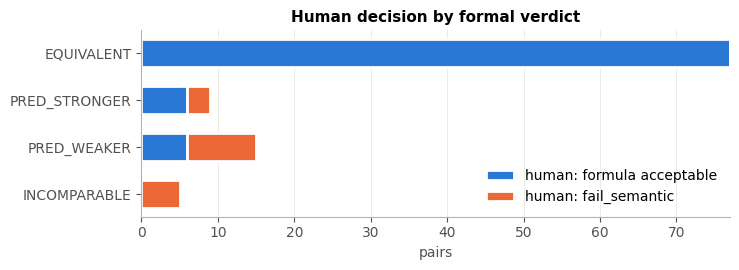

In [6]:
ct = pd.crosstab(d.formal, d.final_decision).reindex(VERDICTS + ['undecided']).fillna(0).astype(int)
ct['accepted %'] = (100 * (ct.get('pass_equivalent', 0) + ct.get('fail_clarification', 0)) / ct.sum(axis=1)).round(0)
display(ct)

fig, ax = plt.subplots(figsize=(7.5, 2.8))
labels = [v for v in VERDICTS if v in ct.index]
acc = ct.loc[labels, ['pass_equivalent', 'fail_clarification']].sum(axis=1)
rej = ct.loc[labels, 'fail_semantic']
y = np.arange(len(labels))[::-1]
ax.barh(y, acc, color=BLUE, height=0.6, edgecolor='white', linewidth=2, label='human: formula acceptable')
ax.barh(y, rej, left=acc, color=ORANGE, height=0.6, edgecolor='white', linewidth=2, label='human: fail_semantic')
ax.set_yticks(y, labels); ax.set_xlabel('pairs'); ax.grid(axis='y', visible=False)
ax.set_title('Human decision by formal verdict'); ax.legend(frameon=False, loc='lower right')
plt.tight_layout(); plt.show()

**Formal `EQUIVALENT` → human always accepts** (no `fail_semantic` among them), so it can auto-accept with
precision 1.0 on this sample. The reverse does not hold: humans accepted a number of formulas that are *not*
equivalent to the gold. Every one of those disagreements was checked by hand. In all cases the tool verdict is
correct relative to the gold formula, and the human judged faithfulness to the *natural-language requirement*:

In [7]:
WHY = {
  'MR-003': 'event vs level: rise(recovery) accepted for "recovery must begin"',
  'MR-008': 'event vs level: rise/fall(output) accepted for "turn on/off"',
  'MR-018': 'event vs level: rise(ack) etc. accepted for response events',
  'MR-026': 'event vs level: rise(response) accepted for "arrives"',
  'MR-039': 'event vs level: rise(valve_A) accepted for "valve A opens"',
  'MR-065': 'event vs level: rise(recovery) accepted for "recovery must begin"',
  'MR-067': 'event vs level: rise(valve_A_open) (label is about the question)',
  'MR-022': 'NL reading: "P unless within 2-4 Q" read as P | F[2,4]Q instead of bounded until',
  'MR-042': 'NL reading: milestones need not be simultaneous (gold demands one joint moment)',
  'MR-043': 'NL reading: ordered milestones (nested F) instead of one joint moment',
  'MR-050': 'NL reading: toll-road avoidance scoped to the 10-min mission horizon',
  'MR-053': 'NL reading: "below" is strict; the gold (<=) is arguably the wrong one',
}
dis = d[(d.formal != 'undecided') & ((d.formal == 'EQUIVALENT') != d.human_accepts_formula)].copy()
dis['explanation'] = dis.pair_id.map(WHY)
display(dis[['pair_id', 'formal', 'final_decision', 'explanation', 'gold', 'pred']])
assert dis.explanation.notna().all(), 'unexplained disagreement - inspect!'

,pair_id,formal,final_decision,explanation,gold,pred
2,MR-003,PRED_STRONGER,pass_equivalent,"event vs level: rise(recovery) accepted for ""recovery must begin""","G(rise(fault = 1) -> F[0,5](G[0,10](recovery = 1)))","G(rise(fault) -> F[0,5](rise(recovery) & G[0,10](recovery)))"
7,MR-008,PRED_STRONGER,pass_equivalent,"event vs level: rise/fall(output) accepted for ""turn on/off""","G(rise(enable = 1) -> F[0,1](output = 1)) & G(fall(enable = 1) -> F[0,1](output = 0))","G((rise(enable = 1)) -> F[0,1](rise(output = 1))) & G((fall(enable = 1)) -> F[0,1](fall(output = 1)))"
17,MR-018,PRED_STRONGER,pass_equivalent,event vs level: rise(ack) etc. accepted for response events,"G(rise(request = 1) -> (F[0,1](ack = 1) & F[0,5](service_started = 1) & F[0,20](service_done = 1)))","G(rise(request) -> (F[0,1](rise(ack)) & F[0,5](rise(service_started)) & F[0,20](rise(service_done))))"
21,MR-022,PRED_WEAKER,pass_equivalent,"NL reading: ""P unless within 2-4 Q"" read as P | F[2,4]Q instead of bounded until","G[20,50](((x1 + x2) <= 1.5) U[2,4](x3 > 2))","G[20,50]((x1 + x2 <= 1.5) | F[2,4](x3 > 2))"
25,MR-026,PRED_STRONGER,pass_equivalent,"event vs level: rise(response) accepted for ""arrives""","G[0,100](rise(request = 1) -> F[0,4](response = 1))","G[0,100](rise(request) -> F[0,4](rise(response)))"
38,MR-039,PRED_WEAKER,pass_equivalent,"event vs level: rise(valve_A) accepted for ""valve A opens""","G(((valve_A = 1) & (valve_B = 0)) -> F[0,3](valve_A = 0))","G((rise(valve_A) & (valve_B = 0)) -> F[0,3](valve_A = 0))"
41,MR-042,PRED_WEAKER,pass_equivalent,NL reading: milestones need not be simultaneous (gold demands one joint moment),G(collision_free) & F(behavior_predicted & safe_region_found & pulled_over & rear_vehicle_passed),G(collision_free) & F(behavior_predicted) & F(safe_region_found) & F(pulled_over) & F(rear_vehicle_passed)
42,MR-043,PRED_WEAKER,pass_equivalent,NL reading: ordered milestones (nested F) instead of one joint moment,G(collision_free) & F(construction_detected & safe_gap_found & lane_merge_completed & journey_resumed),F(construction_detected & F(safe_gap_found & F(lane_merge_completed & F(journey_resumed)))) & G(collision_...
49,MR-050,PRED_WEAKER,pass_equivalent,NL reading: toll-road avoidance scoped to the 10-min mission horizon,"F[0,600](checkpoint_A & F(checkpoint_B & F(destination))) & G(!(toll_road = 1))","F[0,600](checkpoint_A & F(checkpoint_B & F(destination))) & G[0,600](!toll_road)"
52,MR-053,PRED_STRONGER,pass_equivalent,"NL reading: ""below"" is strict; the gold (<=) is arguably the wrong one","G(altitude <= 120) & F[0,90](inspection_point = 1)","G(altitude < 120) & F[0,90](inspection_point = 1)"


Two consequences for the benchmark:

* About half of the accepted non-equivalent pairs are **rise(x) vs x**. If event semantics are intended, the
  *gold* formulas should use `rise`; otherwise these predictions are wrong. This is a dataset decision, and
  the checker makes it visible.
* **Strictness is informative for triage**: no `INCOMPARABLE` pair was accepted, while a sizeable share of
  `PRED_STRONGER` / `PRED_WEAKER` pairs were. A pipeline could auto-accept EQUIVALENT, auto-reject
  INCOMPARABLE, and send only the one-directional cases to a human.

## 6. Runtime

* `spot_ms`: translation + both containment checks, measured inside the worker (process start and IPC excluded).
* `stlsat_ms`: sum of the solver's own `DURATION_SEC` for both SAT queries (`*_wall_ms` includes process start).
* Timeouts: 30 s per SPOT check and per STLSat query.

,n,median ms,p90 ms,max ms,total s,timeouts
Syntactic,110.0,0.25,0.40,0.62,0.03,0.0
SPOT,99.0,0.23,5.11,1632.06,4.64,3.0
STLSat (smt),101.0,17.04,40.00,15786.85,25.84,1.0
STLSat (tableau),95.0,25.46,390.22,2363.58,15.92,7.0
STLSat (smt) wall,102.0,40.53,80.29,60018.19,88.60,1.0


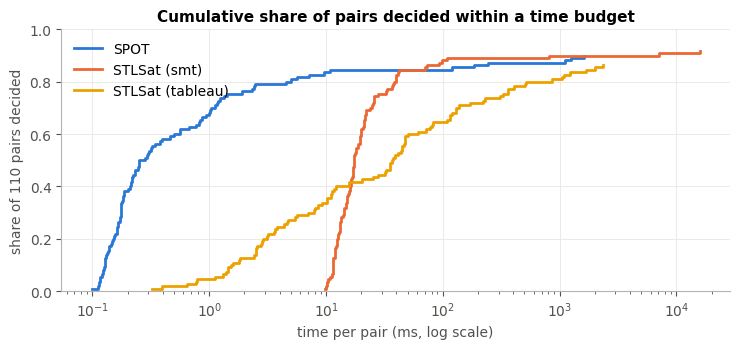

In [8]:
def summary(s, timeouts):
    s = s.dropna()
    return pd.Series({'n': len(s), 'median ms': s.median(), 'p90 ms': s.quantile(.9), 'max ms': s.max(),
                      'total s': s.sum() / 1000, 'timeouts': timeouts})
rt = pd.DataFrame({
    'Syntactic': summary(d.syntactic_ms, 0),
    'SPOT': summary(d.spot_ms, (d.spot_status == 'TIMEOUT').sum()),
    'STLSat (smt)': summary(d.stlsat_ms, (d.stlsat_status == 'TIMEOUT').sum()),
    'STLSat (tableau)': summary(d.tab_stlsat_ms, (d.tab_stlsat_status == 'TIMEOUT').sum()),
    'STLSat (smt) wall': summary(d.stlsat_wall_ms, (d.stlsat_status == 'TIMEOUT').sum()),
}).T
display(rt.round(2))

fig, ax = plt.subplots(figsize=(7.5, 3.6))
for name, col, st in [('SPOT', 'spot_ms', 'spot_status'), ('STLSat (smt)', 'stlsat_ms', 'stlsat_status'),
                      ('STLSat (tableau)', 'tab_stlsat_ms', 'tab_stlsat_status')]:
    s = np.sort(d.loc[d[st] == 'OK', col].dropna().values)
    ax.step(s, np.arange(1, len(s) + 1) / len(d), where='post', color=TOOL_COLOR[name], lw=2, label=name)
ax.set_xscale('log'); ax.set_xlabel('time per pair (ms, log scale)'); ax.set_ylabel('share of 110 pairs decided')
ax.set_ylim(0, 1); ax.set_title('Cumulative share of pairs decided within a time budget'); ax.legend(frameon=False, loc='upper left')
plt.tight_layout(); plt.show()

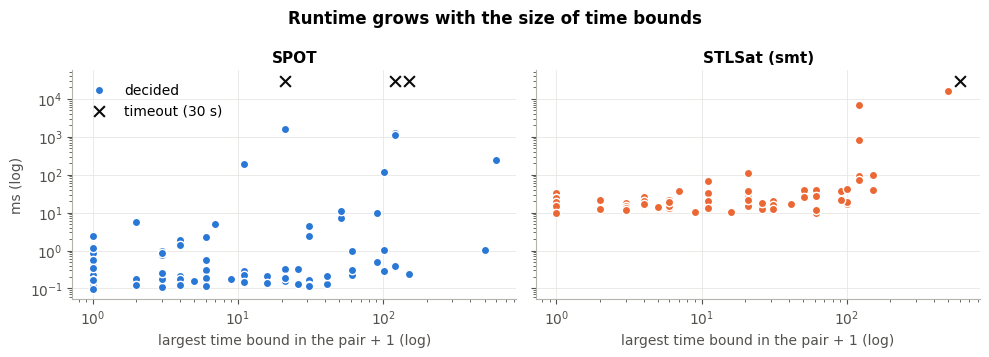

,feature,value,n,SPOT median ms,STLSat smt median ms,STLSat tableau median ms
0,has_past_or_edge,True,29,0.30,18.72,66.66
1,has_past_or_edge,False,81,0.22,16.41,8.52
2,has_unbounded,True,85,0.21,16.64,25.46
3,has_unbounded,False,25,0.30,18.72,63.92


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, (name, col, st) in zip(axes, [('SPOT', 'spot_ms', 'spot_status'), ('STLSat (smt)', 'stlsat_ms', 'stlsat_status')]):
    ok = d[d[st] == 'OK']; to = d[d[st] == 'TIMEOUT']
    ax.scatter(ok.max_bound + 1, ok[col], s=36, color=TOOL_COLOR[name], edgecolor='white', linewidth=1, label='decided')
    ax.scatter(to.max_bound + 1, [30000] * len(to), s=60, marker='x', color='#0b0b0b', label='timeout (30 s)')
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_title(name)
    ax.set_xlabel('largest time bound in the pair + 1 (log)')
axes[0].set_ylabel('ms (log)'); axes[0].legend(frameon=False, loc='upper left')
plt.suptitle('Runtime grows with the size of time bounds', fontweight='bold'); plt.tight_layout(); plt.show()

feat = []
for f in ['has_past_or_edge', 'has_unbounded']:
    for v in [True, False]:
        g = d[d[f] == v]
        feat.append({'feature': f, 'value': v, 'n': len(g), 'SPOT median ms': g.spot_ms.median(),
                     'STLSat smt median ms': g.stlsat_ms.median(), 'STLSat tableau median ms': g.tab_stlsat_ms.median()})
display(pd.DataFrame(feat).round(2))

## 7. Designing a pipeline: which tool(s), in which order?

We simulate cascades from the recorded runtimes. A stage that runs out of budget (or is unsupported) hands
over to the next one. "Decided" counts pairs with a formal verdict. Time is the sum of the solver time spent.

In [10]:
def cascade(stages, budget_ms):
    tot_ms, decided = 0.0, 0
    for _, r in d.iterrows():
        for st in stages:
            if st == 'syn':
                tot_ms += r.syntactic_ms
                if r.syntactic_equal == True: decided += 1; break
                continue
            col, status = {'spot': ('spot_ms', 'spot_status'), 'smt': ('stlsat_ms', 'stlsat_status'),
                           'tab': ('tab_stlsat_ms', 'tab_stlsat_status')}[st]
            t = r[col]
            if r[status] == 'OK' and t <= budget_ms:
                tot_ms += t; decided += 1; break
            if r[status] in ('OK', 'TIMEOUT'):
                tot_ms += budget_ms if (r[status] == 'TIMEOUT' or t > budget_ms) else t
    return decided, tot_ms / 1000

rows = []
for name, stages in [('SPOT only', ['spot']), ('STLSat smt only', ['smt']), ('STLSat tableau only', ['tab']),
                     ('syntactic → SPOT', ['syn', 'spot']), ('syntactic → SPOT → STLSat smt', ['syn', 'spot', 'smt']),
                     ('syntactic → STLSat smt → SPOT', ['syn', 'smt', 'spot'])]:
    for budget in [1000, 5000, 30000]:
        n, t = cascade(stages, budget)
        rows.append({'pipeline': name, 'budget per stage (s)': budget / 1000, 'pairs decided': n, 'solver time (s)': round(t, 1)})
display(pd.DataFrame(rows).pivot(index='pipeline', columns='budget per stage (s)', values=['pairs decided', 'solver time (s)']))

pairs decided               solver time (s)             
budget per stage (s)                   1.0    5.0    30.0            1.0   5.0    30.0
pipeline                                                                              
SPOT only                              96.0   99.0   99.0             6.6  19.6   94.6
STLSat smt only                        99.0   99.0  101.0             6.0  18.0   55.8
STLSat tableau only                    89.0   95.0   95.0            19.5  50.9  225.9
syntactic → SPOT                      100.0  103.0  103.0             6.6  19.7   94.7
syntactic → SPOT → STLSat smt         106.0  106.0  106.0             7.9  20.7   95.7
syntactic → STLSat smt → SPOT         106.0  106.0  106.0             4.1  12.1   47.9

## Conclusions

1. **Correctness.** SPOT and STLSat-smt return the same verdict on all 98 pairs both decide, and the random
   differential test finds no disagreement. The remaining differences from the human labels come from the
   *gold* disagreeing with the *NL*, not from tool errors (section 5). Formal EQUIVALENT ⇒ human accepts, on every pair.
2. **Coverage.** SPOT decides 99 and STLSat-smt 101 of 110 pairs (the old STLSat decided 29). Syntactic +
   SPOT + STLSat together decide 106. The other 4 have symbolic bounds or parameterised operators
   that neither tool supports and that are not syntactically equal.
3. **Runtime.** For the typical pair SPOT is about 70× faster (median 0.23 ms vs 17 ms) and exact on unbounded
   operators, but it blows up on large *nested* bounds. STLSat-smt is slower per pair but more robust to large
   bounds, at the price of horizon capping for unbounded operators (75 of its 101 verdicts). The tableau engine
   is unsound (MR-020) and has the most timeouts.
4. **Pipeline.** The syntactic check removes 70/110 pairs in under a millisecond. After that, both tool orders
   decide the same 106 pairs. With a 1 s budget per stage, *syntactic → STLSat-smt → SPOT* needs about half the
   solver time of *syntactic → SPOT → STLSat* (≈4 s vs ≈8 s here), because SPOT's few blow-ups burn their whole
   budget. Since STLSat's capped verdicts are approximations, *syntactic → SPOT (short budget) → STLSat-smt* is
   the more principled order (exact verdicts first). The time difference is small either way.
   Report the strictness verdict, auto-accept EQUIVALENT, flag INCOMPARABLE, and send one-directional cases to review.